DATASET INFORMATION
------------------------------------------------------------
Dataset shape: (2000, 12)
Number of records: 2000

First five rows:
   age    income  credit_score   loan_amount  loan_term  employment_years  \
0   59   45426.0         527.0  40134.134469         24              28.0   
1   49   37772.0         401.0  44205.463282         36               2.0   
2   35  123754.0         716.0  61620.350552         24              25.0   
3   63   23712.0         515.0  25648.428084         60              13.0   
4   28   21367.0         706.0  39032.375343         36              24.0   

   previous_defaults employment_type marital_status    education  \
0                  0        Contract       Divorced  High School   
1                  0        Salaried       Divorced  High School   
2                  0        Business       Divorced  High School   
3                  2        Salaried        Married     Graduate   
4                  1        Salaried       Divor

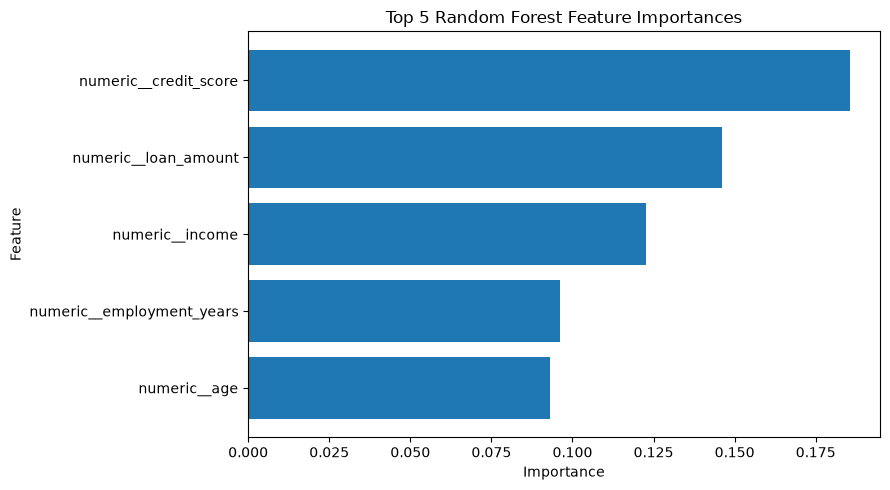


XGBOOST FEATURE IMPORTANCE
------------------------------------------------------------
Top 5 XGBoost Features:
                              Feature  Importance
           numeric__previous_defaults    0.085781
                numeric__credit_score    0.084879
                 numeric__loan_amount    0.071649
categorical__employment_type_Contract    0.056179
                      numeric__income    0.055282


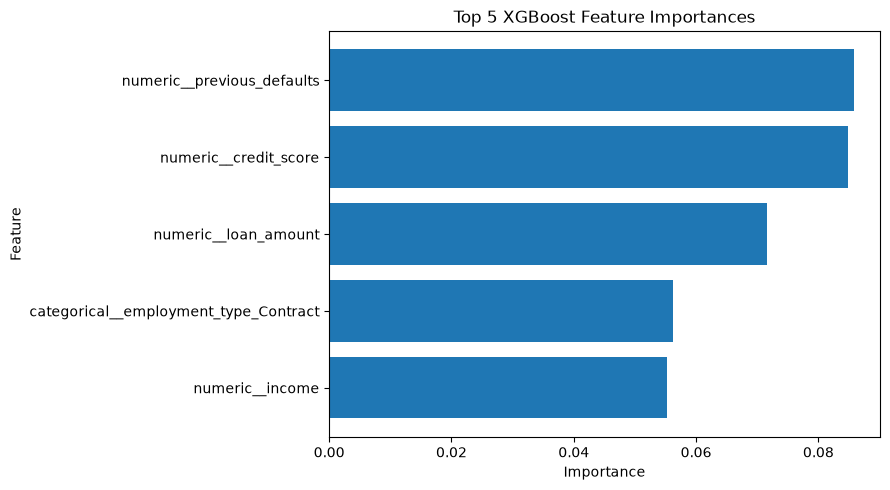


LOAN AMOUNT REGRESSION DATASET
------------------------------------------------------------
Regression training data: (1600, 11)
Regression testing data: (400, 11)

LINEAR REGRESSION
------------------------------------------------------------
Linear Regression R2: 0.4367
Linear Regression RMSE: 26490.63

RIDGE REGRESSION
------------------------------------------------------------
Ridge Regression R2: 0.4367
Ridge Regression RMSE: 26490.23

LASSO REGRESSION
------------------------------------------------------------
Lasso Regression R2: 0.4368
Lasso Regression RMSE: 26488.02

REGRESSION MODEL COMPARISON
------------------------------------------------------------
            Model  R2 Score       RMSE
Linear Regression    0.4367 26490.6350
 Ridge Regression    0.4367 26490.2307
 Lasso Regression    0.4368 26488.0247

REGRESSION COEFFICIENT COMPARISON
------------------------------------------------------------
                                   Feature     Linear      Ridge      Las

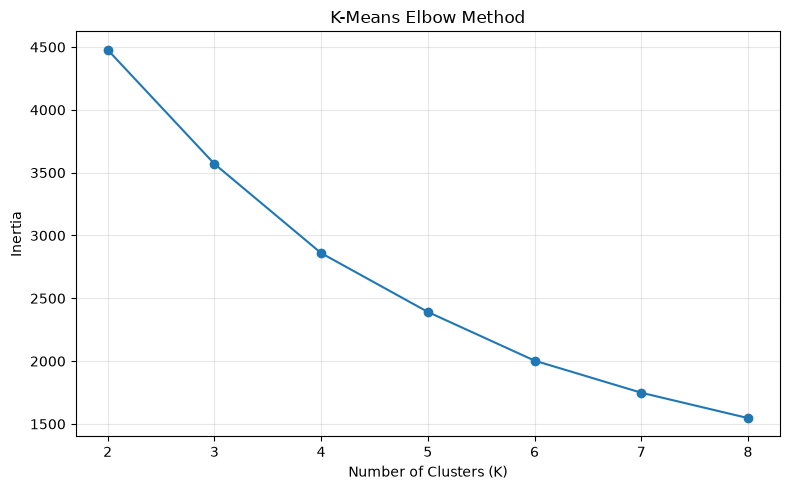

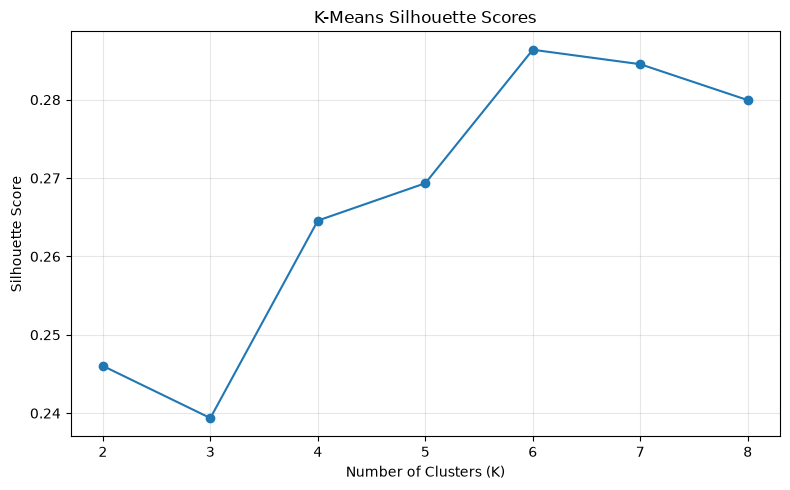


CLUSTER SEGMENTATION
------------------------------------------------------------
Best K based on silhouette score: 6

Cluster Segment Summary:
           age     income  credit_score  Customer Count
cluster                                                
0        50.12  116271.23        743.56             270
1        53.72   49506.55        609.23             422
2        29.53  120901.49        593.48             337
3        52.54  109028.09        432.25             379
4        30.87   54259.06        722.74             292
5        34.37   55017.35        412.83             300

SEGMENT DESCRIPTIONS

Cluster: 0
Customer count: 270
Average age: 50.12
Average income: 116271.23
Average credit score: 743.56

Cluster: 1
Customer count: 422
Average age: 53.72
Average income: 49506.55
Average credit score: 609.23

Cluster: 2
Customer count: 337
Average age: 29.53
Average income: 120901.49
Average credit score: 593.48

Cluster: 3
Customer count: 379
Average age: 52.54
Average income: 1

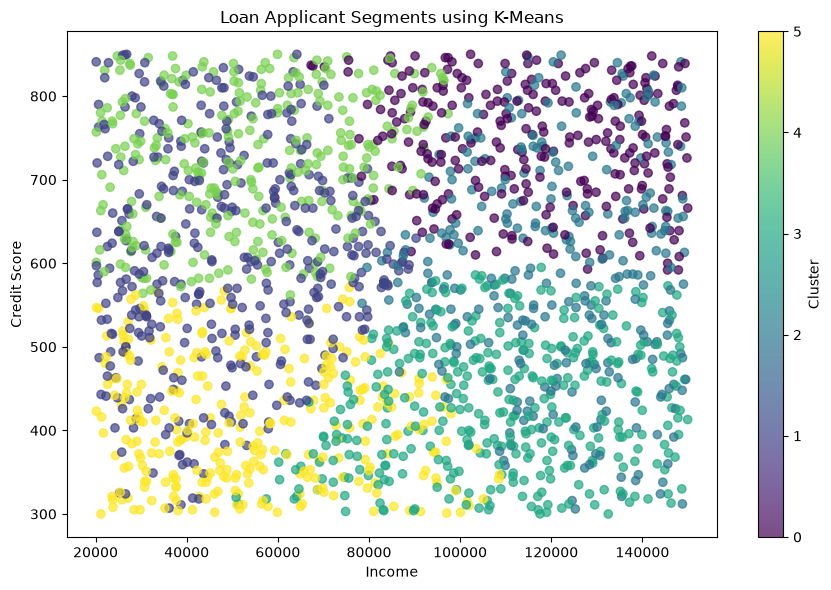


OUTPUT FILE VERIFICATION
------------------------------------------------------------
random_forest_feature_importance.png : Available
xgboost_feature_importance.png : Available
kmeans_elbow_method.png : Available
kmeans_silhouette_scores.png : Available
kmeans_cluster_visualization.png : Available

TASK 3 EXECUTION FINISHED


In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    r2_score,
    mean_squared_error,
    silhouette_score
)

from xgboost import XGBClassifier

np.random.seed(42)
n = 2000

age = np.random.randint(21, 65, n)
income = np.random.randint(20000, 150001, n)
credit_score = np.random.randint(300, 851, n)
loan_term = np.random.choice([12, 24, 36, 48, 60], n)
employment_years = np.random.randint(0, 31, n)

previous_defaults = np.random.choice(
    [0, 1, 2, 3], n, p=[0.72, 0.18, 0.07, 0.03]
)

employment_type = np.random.choice(
    ["Salaried", "Self-employed", "Business", "Contract"], n
)

marital_status = np.random.choice(
    ["Single", "Married", "Divorced"], n
)

education = np.random.choice(
    ["High School", "Graduate", "Postgraduate"], n
)

application_date = pd.to_datetime(
    np.random.choice(
        pd.date_range("2022-01-01", "2025-12-31"), n
    )
)

loan_amount = (
    income * np.random.uniform(0.25, 1.15, n)
    + (credit_score - 300) * 35
    + loan_term * 180
    + np.random.normal(0, 5000, n)
)

loan_amount = np.clip(loan_amount, 5000, 200000)

risk_score = (
    -0.0035 * (credit_score - 600)
    + 0.000012 * (loan_amount - 50000)
    + 0.55 * previous_defaults
    - 0.025 * employment_years
    + np.random.normal(0, 0.45, n)
)

default_probability = 1 / (1 + np.exp(-risk_score))
loan_default = np.random.binomial(1, default_probability)

data = pd.DataFrame({
    "age": age,
    "income": income,
    "credit_score": credit_score,
    "loan_amount": loan_amount,
    "loan_term": loan_term,
    "employment_years": employment_years,
    "previous_defaults": previous_defaults,
    "employment_type": employment_type,
    "marital_status": marital_status,
    "education": education,
    "application_date": application_date,
    "loan_default": loan_default
})

for column in [
    "income",
    "credit_score",
    "employment_years",
    "employment_type"
]:
    missing_indices = data.sample(
        frac=0.03, random_state=42
    ).index

    data.loc[missing_indices, column] = np.nan

print("DATASET INFORMATION")
print("-" * 60)

print("Dataset shape:", data.shape)
print("Number of records:", len(data))
print("\nFirst five rows:")
print(data.head())

print("\nMissing values:")
print(data.isnull().sum())

print("\nLoan default distribution:")
print(data["loan_default"].value_counts())

print("\nDATE FEATURE ENGINEERING")
print("-" * 60)

data["application_month"] = data["application_date"].dt.month
data["application_year"] = data["application_date"].dt.year

data = data.drop(columns=["application_date"])

print("Created application_month and application_year.")
print(data[["application_month", "application_year"]].head())

print("\nCLASSIFICATION DATA SPLITTING")
print("-" * 60)

X = data.drop(columns=["loan_default"])
y = data["loan_default"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

print("\nNUMERIC AND CATEGORICAL COLUMNS")
print("-" * 60)

numeric_columns = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numeric columns:", numeric_columns)
print("Categorical columns:", categorical_columns)

def create_preprocessor(numeric_cols, categorical_cols):
    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, numeric_cols),
            ("categorical", categorical_pipeline, categorical_cols)
        ]
    )

print("\nPREPROCESSING")
print("-" * 60)

preprocessor = create_preprocessor(
    numeric_columns,
    categorical_columns
)

print("ColumnTransformer created successfully.")

print("\nLOGISTIC REGRESSION")
print("-" * 60)

logistic_model = Pipeline(steps=[
    ("preprocessor", create_preprocessor(
        numeric_columns, categorical_columns
    )),
    ("classifier", LogisticRegression(max_iter=2000))
])

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_val)

print(
    "Logistic Regression Accuracy:",
    round(accuracy_score(y_val, logistic_predictions), 4)
)

print("\nDECISION TREE CLASSIFIER")
print("-" * 60)

decision_tree_model = Pipeline(steps=[
    ("preprocessor", create_preprocessor(
        numeric_columns, categorical_columns
    )),
    ("classifier", DecisionTreeClassifier(
        max_depth=6,
        random_state=42
    ))
])

decision_tree_model.fit(X_train, y_train)

decision_tree_predictions = decision_tree_model.predict(X_val)

print(
    "Decision Tree Accuracy:",
    round(accuracy_score(y_val, decision_tree_predictions), 4)
)

print("\nRANDOM FOREST CLASSIFIER WITH OOB")
print("-" * 60)

random_forest_model = Pipeline(steps=[
    ("preprocessor", create_preprocessor(
        numeric_columns, categorical_columns
    )),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=2,
        bootstrap=True,
        oob_score=True,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

forest_predictions = random_forest_model.predict(X_val)

forest_classifier = random_forest_model.named_steps["classifier"]

print(
    "Random Forest Accuracy:",
    round(accuracy_score(y_val, forest_predictions), 4)
)

print(
    "Random Forest OOB Score:",
    round(forest_classifier.oob_score_, 4)
)

print("\nXGBOOST CLASSIFIER WITH EARLY STOPPING")
print("-" * 60)

xgb_preprocessor = create_preprocessor(
    numeric_columns,
    categorical_columns
)

X_train_processed = xgb_preprocessor.fit_transform(X_train)
X_val_processed = xgb_preprocessor.transform(X_val)

xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="binary:logistic",
    eval_metric="logloss",
    early_stopping_rounds=20,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_processed,
    y_train,
    eval_set=[(X_val_processed, y_val)],
    verbose=False
)

xgb_predictions = xgb_model.predict(X_val_processed)

print(
    "XGBoost Accuracy:",
    round(accuracy_score(y_val, xgb_predictions), 4)
)

print("Best iteration:", xgb_model.best_iteration)

print("\nCLASSIFICATION MODEL COMPARISON")
print("-" * 60)

classification_models = {
    "Logistic Regression": logistic_predictions,
    "Decision Tree": decision_tree_predictions,
    "Random Forest": forest_predictions,
    "XGBoost": xgb_predictions
}

classification_results = []

for model_name, predictions in classification_models.items():
    classification_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

classification_results_df = pd.DataFrame(classification_results)

print(classification_results_df.round(4).to_string(index=False))

print("\nPREDICT_PROBA VS PREDICT")
print("-" * 60)

five_rows = X_val.head(5)

class_predictions = logistic_model.predict(five_rows)
class_probabilities = logistic_model.predict_proba(five_rows)

probability_comparison = pd.DataFrame({
    "Actual": y_val.loc[five_rows.index].values,
    "Predicted": class_predictions,
    "Probability_No_Default": class_probabilities[:, 0],
    "Probability_Default": class_probabilities[:, 1]
})

print(probability_comparison.round(4).to_string(index=False))

print("\npredict() returns the predicted class.")
print("predict_proba() returns the probability of each class.")

print("\nRANDOM FOREST FEATURE IMPORTANCE")
print("-" * 60)

forest_feature_names = random_forest_model.named_steps[
    "preprocessor"
].get_feature_names_out()

forest_importance = pd.DataFrame({
    "Feature": forest_feature_names,
    "Importance": forest_classifier.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Top 5 Random Forest Features:")
print(forest_importance.head(5).to_string(index=False))

plt.figure(figsize=(9, 5))
plt.barh(
    forest_importance.head(5)["Feature"],
    forest_importance.head(5)["Importance"]
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 5 Random Forest Feature Importances")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(
    "random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("\nXGBOOST FEATURE IMPORTANCE")
print("-" * 60)

xgb_feature_names = xgb_preprocessor.get_feature_names_out()

xgb_importance = pd.DataFrame({
    "Feature": xgb_feature_names,
    "Importance": xgb_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Top 5 XGBoost Features:")
print(xgb_importance.head(5).to_string(index=False))

plt.figure(figsize=(9, 5))
plt.barh(
    xgb_importance.head(5)["Feature"],
    xgb_importance.head(5)["Importance"]
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 5 XGBoost Feature Importances")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(
    "xgboost_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("\nLOAN AMOUNT REGRESSION DATASET")
print("-" * 60)

X_reg = data.drop(columns=["loan_amount", "loan_default"])
y_reg = data["loan_amount"]

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

reg_numeric_columns = X_reg_train.select_dtypes(
    include=np.number
).columns.tolist()

reg_categorical_columns = X_reg_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Regression training data:", X_reg_train.shape)
print("Regression testing data:", X_reg_test.shape)

def create_reg_preprocessor():
    return ColumnTransformer(
        transformers=[
            (
                "numeric",
                Pipeline(steps=[
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler())
                ]),
                reg_numeric_columns
            ),
            (
                "categorical",
                Pipeline(steps=[
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("encoder", OneHotEncoder(handle_unknown="ignore"))
                ]),
                reg_categorical_columns
            )
        ]
    )

print("\nLINEAR REGRESSION")
print("-" * 60)

linear_model = Pipeline(steps=[
    ("preprocessor", create_reg_preprocessor()),
    ("regressor", LinearRegression())
])

linear_model.fit(X_reg_train, y_reg_train)

linear_predictions = linear_model.predict(X_reg_test)

print(
    "Linear Regression R2:",
    round(r2_score(y_reg_test, linear_predictions), 4)
)

print(
    "Linear Regression RMSE:",
    round(np.sqrt(mean_squared_error(
        y_reg_test, linear_predictions
    )), 2)
)

print("\nRIDGE REGRESSION")
print("-" * 60)

ridge_model = Pipeline(steps=[
    ("preprocessor", create_reg_preprocessor()),
    ("regressor", Ridge(alpha=1.0))
])

ridge_model.fit(X_reg_train, y_reg_train)

ridge_predictions = ridge_model.predict(X_reg_test)

print(
    "Ridge Regression R2:",
    round(r2_score(y_reg_test, ridge_predictions), 4)
)

print(
    "Ridge Regression RMSE:",
    round(np.sqrt(mean_squared_error(
        y_reg_test, ridge_predictions
    )), 2)
)

print("\nLASSO REGRESSION")
print("-" * 60)

lasso_model = Pipeline(steps=[
    ("preprocessor", create_reg_preprocessor()),
    ("regressor", Lasso(alpha=10.0, max_iter=10000))
])

lasso_model.fit(X_reg_train, y_reg_train)

lasso_predictions = lasso_model.predict(X_reg_test)

print(
    "Lasso Regression R2:",
    round(r2_score(y_reg_test, lasso_predictions), 4)
)

print(
    "Lasso Regression RMSE:",
    round(np.sqrt(mean_squared_error(
        y_reg_test, lasso_predictions
    )), 2)
)

print("\nREGRESSION MODEL COMPARISON")
print("-" * 60)

regression_results = []

for name, predictions in [
    ("Linear Regression", linear_predictions),
    ("Ridge Regression", ridge_predictions),
    ("Lasso Regression", lasso_predictions)
]:
    regression_results.append({
        "Model": name,
        "R2 Score": r2_score(y_reg_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(
            y_reg_test, predictions
        ))
    })

regression_results_df = pd.DataFrame(regression_results)

print(regression_results_df.round(4).to_string(index=False))

print("\nREGRESSION COEFFICIENT COMPARISON")
print("-" * 60)

reg_feature_names = (
    linear_model.named_steps["preprocessor"].get_feature_names_out()
)

coefficient_comparison = pd.DataFrame({
    "Feature": reg_feature_names,
    "Linear": linear_model.named_steps["regressor"].coef_,
    "Ridge": ridge_model.named_steps["regressor"].coef_,
    "Lasso": lasso_model.named_steps["regressor"].coef_
})

print(coefficient_comparison.round(4).to_string(index=False))

lasso_coefficients = lasso_model.named_steps["regressor"].coef_

zero_coefficients = np.sum(
    np.isclose(lasso_coefficients, 0, atol=1e-8)
)

print("\nNumber of zero Lasso coefficients:", zero_coefficients)
print("Total Lasso coefficients:", len(lasso_coefficients))

print("\nK-MEANS CLUSTERING")
print("-" * 60)

cluster_columns = [
    "age",
    "income",
    "credit_score"
]

cluster_imputer = SimpleImputer(strategy="median")
cluster_scaler = StandardScaler()

cluster_data_imputed = cluster_imputer.fit_transform(
    data[cluster_columns]
)

cluster_data = cluster_scaler.fit_transform(
    cluster_data_imputed
)

print("Clustering columns:", cluster_columns)
print("K values tested: 2 to 8")

print("\nELBOW METHOD AND SILHOUETTE SCORES")
print("-" * 60)

inertia_values = []
silhouette_values = []
k_values = range(2, 9)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(cluster_data)

    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(
        silhouette_score(cluster_data, cluster_labels)
    )

clustering_results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

print(clustering_results.round(4).to_string(index=False))

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    "kmeans_elbow_method.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-Means Silhouette Scores")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    "kmeans_silhouette_scores.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("\nCLUSTER SEGMENTATION")
print("-" * 60)

best_k = int(
    clustering_results.loc[
        clustering_results["Silhouette Score"].idxmax(),
        "K"
    ]
)

final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

data["cluster"] = final_kmeans.fit_predict(cluster_data)

print("Best K based on silhouette score:", best_k)

segment_summary = data.groupby("cluster")[
    cluster_columns
].mean().round(2)

segment_summary["Customer Count"] = data.groupby("cluster").size()

print("\nCluster Segment Summary:")
print(segment_summary.to_string())

print("\nSEGMENT DESCRIPTIONS")

for cluster_number, row in segment_summary.iterrows():
    print("\nCluster:", cluster_number)
    print("Customer count:", int(row["Customer Count"]))
    print("Average age:", round(row["age"], 2))
    print("Average income:", round(row["income"], 2))
    print("Average credit score:", round(row["credit_score"], 2))

print("\nCLUSTER VISUALIZATION")
print("-" * 60)

cluster_plot_data = pd.DataFrame(
    cluster_data_imputed,
    columns=cluster_columns,
    index=data.index
)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    cluster_plot_data["income"],
    cluster_plot_data["credit_score"],
    c=data["cluster"],
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Income")
plt.ylabel("Credit Score")
plt.title("Loan Applicant Segments using K-Means")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.savefig(
    "kmeans_cluster_visualization.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("\nOUTPUT FILE VERIFICATION")
print("-" * 60)

output_files = [
    "random_forest_feature_importance.png",
    "xgboost_feature_importance.png",
    "kmeans_elbow_method.png",
    "kmeans_silhouette_scores.png",
    "kmeans_cluster_visualization.png"
]

for filename in output_files:
    if os.path.exists(filename):
        print(filename, ": Available")
    else:
        print(filename, ": Missing")

